<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px">

# Hyperparameters, GridSearch, and Pipelines

_Authors: Kiefer Katovich, David Yerrington, Matt Brems, Noelle Brown_

---

![](https://snag.gy/aYcCt2.jpg)

### Learning Objectives
- Describe what the terms hyperparameters, GridSearch, and pipeline mean.
- Apply `sklearn`'s `GridSearchCV` object.
- Use attributes of the GridSearch object.
- Describe the pitfalls of searching large hyperparameter spaces.
- Build pipelines.

In [1]:
#Imports!
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

In [2]:
# Column names.
abalone_colnames = [
    'sex', 'length', 'diameter', 'height', 'whole_weight',
    'shucked_weight', 'viscera_weight', 'shell_weight', 'rings'
]

# Pass in column names on import.
ab = pd.read_csv('../data/abalone.data', names=abalone_colnames)
ab.head()

,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [3]:
# How many rows/columns?
ab.shape

(4177, 9)

In [4]:
# Any missing values?
ab.isna().sum()

sex               0
length            0
diameter          0
height            0
whole_weight      0
shucked_weight    0
viscera_weight    0
shell_weight      0
rings             0
dtype: int64

### Let's Whiz Through the Boring Parts
Quickly so as to get to the fun parts, I'll:
* Create our `X` and `y`. We'll be doing a kNN, so we won't use `sex`.
* Do a train-test split.
* Scale our data.

In [5]:
# Define y.
y = ab['rings']

# Define X without rings or sex.
X = ab.drop(columns=['sex', 'rings'])

# Set up a train-test split.
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=2022)

# Instantiate and fit StandardScaler, then transform our training and testing data.
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

# GridSearch
> _Oftentimes, we'll prefer RandomizedSearch. But, GridSearch is a good place to start!_

Up until now, we've tuned our hyperparameters (also called "tuning parameters") either automatically using some `sklearn` tech, or via sloppy loops. `sklearn` gives us some fun tools for automating this process in many cases. I'll demonstrate with a simple kNN first.

In [6]:
# Instantiate a k-nearest neighbors model for regression.
knn = KNeighborsRegressor()

# Set up our grid of hyperparameters.
hyperparams = {'n_neighbors': np.arange(1, 202, 5)}

# Instantiate our GridSearchCV object.
gs = GridSearchCV(estimator=knn,
                  param_grid=hyperparams)

In [7]:
# Let's cross-validate over some values of k.
gs.fit(X_train_sc, y_train);

In [8]:
# What is our best value of k?
gs.best_params_

# How is that measured?

{'n_neighbors': 31}

In [9]:
# Let's retrieve our best estimator.
gs.best_estimator_

KNeighborsRegressor(n_neighbors=31)

In [10]:
# Let's look at our cross-validated results!
pd.DataFrame(gs.cv_results_).head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_n_neighbors,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.002341,0.000293,0.006192,0.001152,1,{'n_neighbors': 1},0.208134,0.143136,0.189533,0.212117,0.234357,0.197455,0.030673,41
1,0.001971,0.000066,0.007621,0.000550,6,{'n_neighbors': 6},0.462631,0.528564,0.490114,0.452478,0.525148,0.491787,0.031189,24
2,0.001817,0.000087,0.008466,0.000176,11,{'n_neighbors': 11},0.509811,0.542607,0.510713,0.489675,0.553135,0.521188,0.023288,9
3,0.001833,0.000129,0.009534,0.000166,16,{'n_neighbors': 16},0.522055,0.554505,0.519089,0.494522,0.558949,0.529824,0.023997,4
4,0.001796,0.000080,0.010661,0.000579,21,{'n_neighbors': 21},0.521562,0.551017,0.520809,0.491308,0.569272,0.530794,0.026958,3


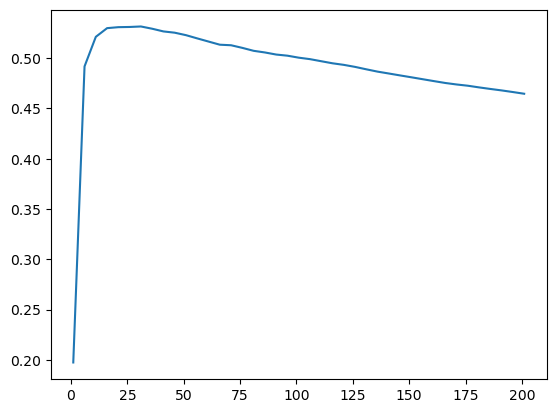

In [11]:
# Let's plot these results.
df_gs = pd.DataFrame(gs.cv_results_)
plt.plot(df_gs.param_n_neighbors, df_gs.mean_test_score);

This is cool!!! And we actually have `gs.best_estimator_` already fit as our optional model. But there's actually one more piece of efficiency `sklearn` can give us:

# Pipelines
Pipelines in `sklearn` allow you to combine several steps into one `estimator` or `transformer` object. 

That is, you can have pipelines of two forms:
1. one or more transformers (note this is the same as using a `ColumnTransformer` on all columns)
2. one or more transformers, with one estimator as the final stage

In [12]:
# Instantiate a Pipeline which will scale our columns and then build a kNN model with 31 neighbors.
pipe = Pipeline([
    ('sc', StandardScaler()),
    ('knn', KNeighborsRegressor(n_neighbors=31))
])

In [13]:
# After instantiating, let's fit our Pipeline to our training data.
pipe.fit(X_train, y_train)

Pipeline(steps=[('sc', StandardScaler()),
                ('knn', KNeighborsRegressor(n_neighbors=31))])

In [14]:
# Now, let's pass our testing data through our already-fit Pipeline.
pipe.score(X_test, y_test)

0.4991063297213687

# Pipelines + GridSearch - All together, now!
You can, of course, use these all in conjunction. Let's try a new example with different data.

We'll use data on heart disease from a studen on men in Western Cape, South Africa. You can find a better description of the data [here](https://hastie.su.domains/ElemStatLearn/datasets/SAheart.info.txt).

In [15]:
# Read in our heart data. What do you notice about famhist?
heart = pd.read_csv('../data/SAheart.data')
heart.head()

,row.names,sbp,tobacco,ldl,adiposity,famhist,typea,obesity,alcohol,age,chd
0,1,160,12.00,5.73,23.11,Present,49,25.30,97.20,52,1
1,2,144,0.01,4.41,28.61,Absent,55,28.87,2.06,63,1
2,3,118,0.08,3.48,32.28,Present,52,29.14,3.81,46,0
3,4,170,7.50,6.41,38.03,Present,51,31.99,24.26,58,1
4,5,134,13.60,3.50,27.78,Present,60,25.99,57.34,49,1


In [16]:
# Here's a new way to convert a variable to 1s and 0s.
# Generate the series of Trues/Falses based on the condition.
# Multiplied by 1 will convert True --> 1 and False --> 0.
heart['famhist'] = (heart['famhist'] == 'Present') * 1 

# See our results.
heart.head()

# This is really only good for generating a single dummy variable.

,row.names,sbp,tobacco,ldl,adiposity,famhist,typea,obesity,alcohol,age,chd
0,1,160,12.00,5.73,23.11,1,49,25.30,97.20,52,1
1,2,144,0.01,4.41,28.61,0,55,28.87,2.06,63,1
2,3,118,0.08,3.48,32.28,1,52,29.14,3.81,46,0
3,4,170,7.50,6.41,38.03,1,51,31.99,24.26,58,1
4,5,134,13.60,3.50,27.78,1,60,25.99,57.34,49,1


In [17]:
# Define X and y.
X = heart.drop(columns=['row.names', 'chd'])
y = heart['chd']

In [18]:
# Train/test split.
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=2022)

### Warning! You could accidentally make too many pairs of parameters and your model could take an extremely long time to fit! Start small.

In [19]:
# Set up hyperparameters dictionary.
hyperparams = {
    'lr__penalty': ['l1', 'l2'],
    'lr__C': np.logspace(-2, 0, 100)
}

# Instantiate Pipeline to scale and build a logistic regression model.
pipe = Pipeline([
    ('sc', StandardScaler()),
    ('lr', LogisticRegression(solver='liblinear'))
])

# Instantiate our GridSearchCV object, so that we can get ready to fit this on our training data.
gs = GridSearchCV(pipe, param_grid=hyperparams, n_jobs=8)

In [20]:
%%time
# Let's time our work.

# Fit our GridSearchCV object to the training data.
gs.fit(X_train, y_train)

CPU times: user 1.03 s, sys: 205 ms, total: 1.23 s
Wall time: 5.13 s


GridSearchCV(estimator=Pipeline(steps=[('sc', StandardScaler()),
                                       ('lr',
                                        LogisticRegression(solver='liblinear'))]),
             n_jobs=8,
             param_grid={'lr__C': array([0.01      , 0.01047616, 0.01097499, 0.01149757, 0.01204504,
       0.01261857, 0.01321941, 0.01384886, 0.01450829, 0.01519911,
       0.01592283, 0.01668101, 0.01747528, 0.01830738, 0.0191791 ,
       0.02009233, 0.02104904, 0.02205131, 0.0231013 , 0....
       0.20565123, 0.21544347, 0.22570197, 0.23644894, 0.24770764,
       0.25950242, 0.27185882, 0.28480359, 0.29836472, 0.31257158,
       0.32745492, 0.34304693, 0.35938137, 0.37649358, 0.39442061,
       0.41320124, 0.43287613, 0.45348785, 0.47508102, 0.49770236,
       0.52140083, 0.54622772, 0.57223677, 0.59948425, 0.62802914,
       0.65793322, 0.68926121, 0.7220809 , 0.75646333, 0.7924829 ,
       0.83021757, 0.869749  , 0.91116276, 0.95454846, 1.        ]),
                         'lr__penalty': ['l1', 'l2']})

In [21]:
# Let's store our cross-validated results, so that we can use them later.
df_gs = pd.DataFrame(gs.cv_results_)

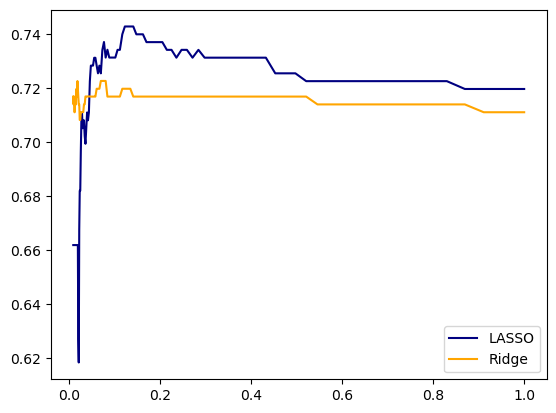

In [22]:
# Let's plot these results.

plt.plot(
    df_gs.loc[df_gs.param_lr__penalty == 'l1', 'param_lr__C'],
    df_gs.loc[df_gs.param_lr__penalty == 'l1', 'mean_test_score'],
    c='navy',
    label='LASSO'
)
plt.plot(
    df_gs.loc[df_gs.param_lr__penalty == 'l2', 'param_lr__C'],
    df_gs.loc[df_gs.param_lr__penalty == 'l2', 'mean_test_score'],
    c='orange',
    label='Ridge'
)
plt.legend(loc=4);

In [23]:
# What are the best parameters of our model?
gs.best_params_

{'lr__C': 0.12328467394420665, 'lr__penalty': 'l1'}

## A Word of Caution on GridSearching

`sklearn` models often have many hyperparameters with many different possible values. It may be tempting to search over a wide variety of them. In general, this is not wise.

<details><summary>Why not?</summary>

- Remember that GridSearch searches over **all possible combinations of hyperparameters in the parameter dictionary!**

Imagine that we had this as our parameter dictionary:

```python
hyperparam_grid = {
    'n_neighbors': range(1, 151),
    'weights': ['uniform', 'distance', custom_function],
    'algorithm': ['ball_tree', 'kd_tree', 'brute', 'auto'],
    'leaf_size': range(1, 152),
    'metric': ['minkowski', 'euclidean'],
    'p': [1, 2]
}
```

**How many different combinations will need to be tested?**

| Hyperparameter | Number of Chosen Values |
| --- | --- |
| **n_neighbors** | 150 |
| **weights** | 3 |
| **algorithm** | 4 |
| **leaf_size** | 151 |
| **metric** | 2 |
| **p** | 2 |
| <br>_150 \* 3 \* 4 \* 151 \* 2 \* 2 = n combinations_ <br><br>| _1,087,200_ |

If we select `cv = 5`, we would fit 1,087,200 models on five folds, meaning we fit 5,436,000 models!

If you're not careful, GridSearching can quickly scale out of hand computationally.

> **It is extremely important to understand what the hyperparameters do and think critically about what ranges are useful and relevant to your model!**
</details>

## Alternative: RandomSearchCV
**Random searching** (aka **stochastic searching**) is a much more recommended method for large parameter spaces. It choses tuning parameter combinations at random to "visit" more of the parameter space without doing an exhaustive search.

In [24]:
from sklearn.model_selection import RandomizedSearchCV

In [25]:
# RandomizedSearchCV()

## Interview Question

<details><summary>What is the difference between hyperparameters and statistical parameters?</summary>
    
- Statistical parameters are quantities that a model can learn or estimate. Examples include $\beta_0$ and $\beta_1$ in a linear model.
- Hyperparameters are quantities our model cannot learn, but affect the fit of our model. Examples include $k$ in $k$-nearest neighbors and $alpha$ in regularization.
</details>